# Phase 4: Fire management under drought

A drought year: 70% tree cover and q = 0.92 (normal-year q = 0.6, dryness 0.8). A single lightning strike hits a random tree. Before the fire season we may remove some trees in one of three ways:

* **Firebreaks:** straight cleared lines in a grid, splitting the forest into compartments.
* **Random thinning:** remove trees at random everywhere.
* **Controlled burns:** burn square patches on purpose in the wet season.

Question: **which saves the most forest per tree removed?** Every strategy is tested on the same 100 forests and lightning strikes.

In [1]:
# Setup: works locally (run from notebooks/) and in Google Colab.
# In Colab the code is cloned from GitHub if that repo exists; otherwise copy the project folder
# to Google Drive as MyDrive/forest_fire.
import os, subprocess, sys
if "google.colab" in sys.modules and not os.path.isdir("src/forest_fire"):
    repo = "https://github.com/nhamhhung/forest-fire-spread.git"
    if subprocess.run(["git", "clone", "-q", repo, "/content/forest_fire"]).returncode == 0:
        os.chdir("/content/forest_fire")
    else:
        from google.colab import drive
        drive.mount("/content/drive")
        os.chdir("/content/drive/MyDrive/forest_fire")
    subprocess.run([sys.executable, "-m", "pip", "-q", "install", "numba"], check=True)
root = os.path.abspath("..") if os.path.basename(os.getcwd()) == "notebooks" else os.getcwd()
sys.path.insert(0, os.path.join(root, "src"))

import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from dataclasses import replace
from forest_fire import experiments as ex
from forest_fire.management import treat
from forest_fire.grid import TREE, make_forest, ignite_point
from forest_fire.spread import run_fire
from forest_fire.plotting import plot_managed
s = ex.Phase4Settings()
print(f"drought spread probability q = {s.q:.2f}")

drought spread probability q = 0.92


## 1. One forest, one strike, three treatments (8% of trees removed)

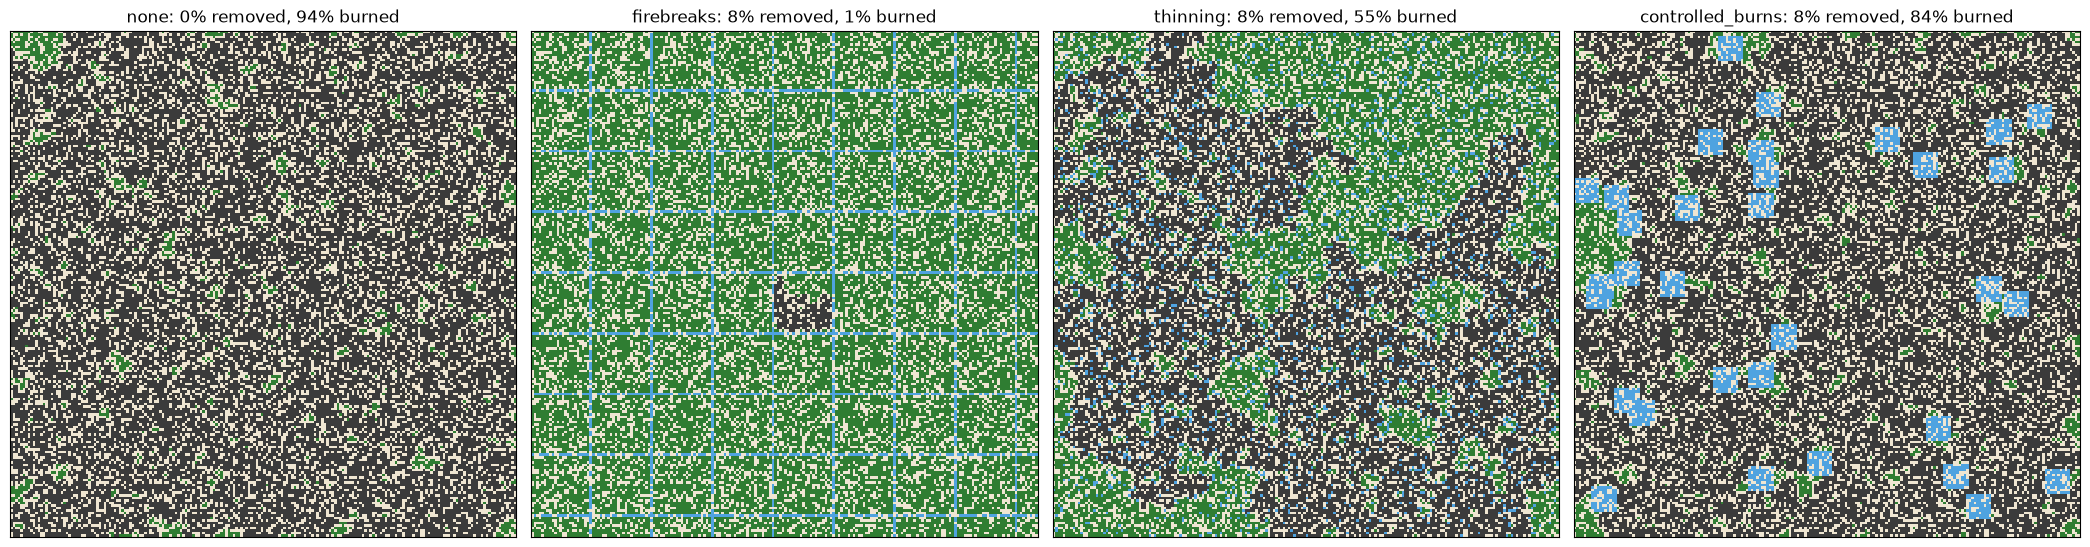

In [2]:
forest = make_forest(s.size, s.density, np.random.default_rng(31))
r, c, fire_seed = 99, 99, 0   # a strike inside the forest's big connected cluster (see scripts/run_phase4.py)
n = (forest == TREE).sum()
fig, axes = plt.subplots(1, 4, figsize=(21, 5.4))
for ax, strategy in zip(axes, ["none", "firebreaks", "thinning", "controlled_burns"]):
    treated, removed = treat(forest, strategy, 0.08, np.random.default_rng([31, 1]), s.burn_patch)
    treated[r, c] = TREE
    final, _, _ = run_fire(ignite_point(treated, r, c), s.q, s.neighbourhood, fire_seed)
    loss = ((final == 3) & (treated == TREE)).sum() / n
    plot_managed(forest, treated, final, ax=ax, title=f"{strategy}: {removed/n:.0%} removed, {loss:.0%} burned")
plt.tight_layout(); plt.show()

Blue = removed beforehand, dark grey = burned by the wildfire, green = survived.

## 2. All budgets, averaged over 100 forests

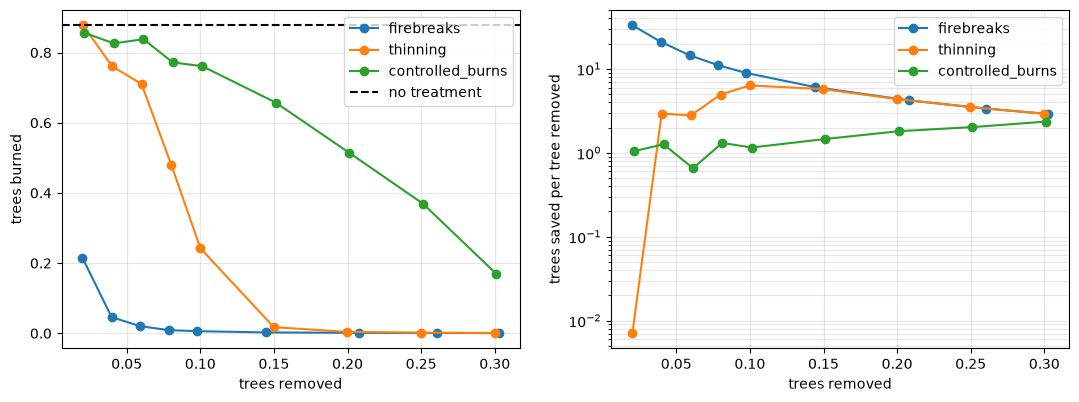

,strategy,budget,removed,loss,total_loss,trees_saved_per_tree_removed
0,controlled_burns,0.02,0.021,0.856,0.878,1.046
1,controlled_burns,0.04,0.041,0.826,0.868,1.265
2,controlled_burns,0.06,0.061,0.838,0.900,0.655
3,controlled_burns,0.08,0.081,0.772,0.853,1.311
4,controlled_burns,0.10,0.101,0.761,0.863,1.157
5,controlled_burns,0.15,0.151,0.658,0.809,1.461
6,controlled_burns,0.20,0.201,0.515,0.716,1.810
7,controlled_burns,0.25,0.251,0.370,0.621,2.026
8,controlled_burns,0.30,0.301,0.170,0.471,2.355
9,firebreaks,0.02,0.020,0.215,0.235,33.310


In [3]:
runs = ex.management_sweep(s)
sm = ex.summarise_management(runs)
base = sm.loc[sm.strategy == "none", "loss"].iloc[0]
fig, axes = plt.subplots(1, 2, figsize=(13, 4.4))
for strategy in s.strategies:
    d = sm[sm.strategy == strategy]
    axes[0].plot(d["removed"], d["loss"], "o-", label=strategy)
    axes[1].plot(d["removed"], d["trees_saved_per_tree_removed"], "o-", label=strategy)
axes[0].axhline(base, color="k", ls="--", label="no treatment"); axes[0].set(xlabel="trees removed", ylabel="trees burned")
axes[1].set(xlabel="trees removed", ylabel="trees saved per tree removed", yscale="log")
for ax in axes: ax.legend(); ax.grid(alpha=.3, which="both")
plt.show()
sm[["strategy", "budget", "removed", "loss", "total_loss", "trees_saved_per_tree_removed"]].round(3)

* **Firebreaks are the most efficient by far.** Clearing 2% of trees cuts the burn from 88% to about 21%, saving 33 trees per tree removed. The fire is trapped in its compartment.
* **Random thinning works only past a threshold.** It does little until it pushes the forest below the critical density (≈ 0.63 at q = 0.92), then the burn collapses: 24% burned at 10% removed, 2% at 15%.
* **Random controlled-burn patches are the weakest.** Scattered patches never cut the forest's connectivity: 30% removed still leaves 17% burned. Patches placed as strips would act like firebreaks.

## 3. Do firebreaks survive embers?
Real fires jump gaps with wind-blown embers. Each burning cell, each step, throws an ember with some probability, landing up to R cells away.

In [4]:
rows = []
for name, prob, radius in [("no embers", 0, 0), ("1%/step, 5 cells", 0.01, 5), ("5%/step, 10 cells", 0.05, 10)]:
    si = replace(s, spot_prob=prob, spot_radius=radius, budgets=[0.04, 0.10, 0.20], n_runs=60)
    rows.append(ex.summarise_management(ex.management_sweep(si)).assign(embers=name))
emb = pd.concat(rows)
emb.pivot_table(index=["strategy", "budget"], columns="embers", values="loss").round(3)

embers                   1%/step, 5 cells  5%/step, 10 cells  no embers
strategy         budget                                                
controlled_burns 0.04               0.841              0.880      0.809
                 0.10               0.797              0.814      0.762
                 0.20               0.572              0.686      0.549
firebreaks       0.04               0.065              0.675      0.043
                 0.10               0.007              0.103      0.006
                 0.20               0.001              0.003      0.001
none             0.00               0.868              0.876      0.866
thinning         0.04               0.776              0.845      0.783
                 0.10               0.248              0.633      0.201
                 0.20               0.005              0.016      0.003

## Takeaways
* Breaking **connectivity** matters more than reducing **amount** of fuel. Firebreaks cut the forest into pieces smaller than the fire's reach, so they beat the other strategies at every budget.
* **Embers change the picture at low budgets.** With strong spotting (5% per step, 10 cells), widely spaced breaks (4% budget) let most fires escape, while closely spaced ones (10%) still hold. In an El Niño drought with strong winds, firebreaks need to be denser or wider.
* Thinning has a cliff: removing too little is nearly useless, enough to drop below the critical density works well. That is the same percolation threshold as in Phases 1–3.